In [2]:
from tensorflow.keras.datasets import mnist
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
import keras

# 1.1 Dataset laden

(x_train, y_train), (x_test, y_test) = mnist.load_data()
 
# Überblick verschaffen
print("Trainingsdaten Shape:", x_train.shape)
print("Testdaten Shape:", x_test.shape)
 
 

Trainingsdaten Shape: (60000, 28, 28)
Testdaten Shape: (10000, 28, 28)


In [4]:
# 1.2 DataFrame erstellen 

x_train_flattened = x_train.reshape(x_train.shape[0], 28 * 28)
df_images = pd.DataFrame(x_train_flattened)
print(df_images.head())
 

   0    1    2    3    4    5    6    7    8    9    ...  774  775  776  777  \
0    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
1    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
2    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
3    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
4    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   

   778  779  780  781  782  783  
0    0    0    0    0    0    0  
1    0    0    0    0    0    0  
2    0    0    0    0    0    0  
3    0    0    0    0    0    0  
4    0    0    0    0    0    0  

[5 rows x 784 columns]


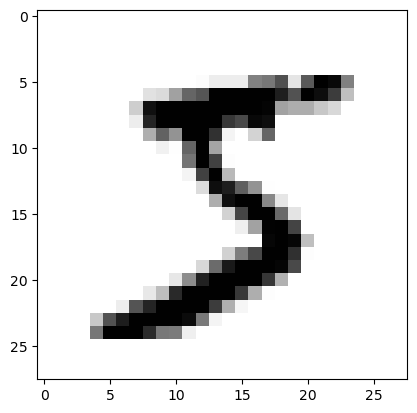

In [5]:
# 1.3 Ziffer an Position 0 anzeigen

plt.imshow(x_train[0], cmap="gray_r")
plt.show()
 

In [6]:
# 1.4 - Warum 10 Knoten im Output-Layer? Weil es 10 Ziffern von 0 bis 9 gibt.
# 1.5 Modell definieren und kompilieren
 
model = tf.keras.Sequential()
model.add(tf.keras.layers.Dense(64, activation="relu", input_shape=(784,)))
model.add(tf.keras.layers.Dense(10, activation="softmax"))
 
model.compile(
    optimizer="rmsprop",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
 

C:\Users\fabio\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
# 1.6 Datenaufbereitung (One-Hot & Reshape) & Training

y_train_onehot = tf.keras.utils.to_categorical(y_train, num_classes=10)
y_test_onehot = tf.keras.utils.to_categorical(y_test, num_classes=10)
 
# Reshape und Normalisierung der Bilder
x_train = x_train.reshape(x_train.shape[0], x_train.shape[1] * x_train.shape[2])
x_train = x_train.astype("float32") / 255.0
 
x_test = x_test.reshape(x_test.shape[0], x_test.shape[1] * x_test.shape[2])
x_test = x_test.astype("float32") / 255.0
 
# Modell trainieren
history_other = model.fit(
    x_train, 
    y_train_onehot, 
    epochs=5, 
    batch_size=128, 
    validation_data=(x_test, y_test_onehot)
)
 
 

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8958 - loss: 0.3875 - val_accuracy: 0.9350 - val_loss: 0.2219
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9435 - loss: 0.1972 - val_accuracy: 0.9501 - val_loss: 0.1677
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9566 - loss: 0.1520 - val_accuracy: 0.9573 - val_loss: 0.1407
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9637 - loss: 0.1248 - val_accuracy: 0.9638 - val_loss: 0.1207
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9698 - loss: 0.1064 - val_accuracy: 0.9670 - val_loss: 0.1123


In [8]:
# 1.7 Modell validieren / evaluieren

test_loss, test_acc = model.evaluate(x_test, y_test_onehot)
print(f"Testgenauigkeit (Accuracy): {test_acc}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 654us/step - accuracy: 0.9670 - loss: 0.1123
Testgenauigkeit (Accuracy): 0.9670000076293945


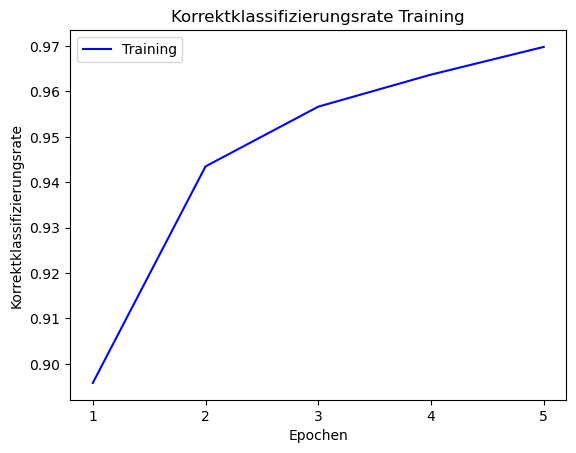

In [9]:
# Aufgabe 18.2.1: Plot der Accuracy basierend auf der fit-History
epochs = len(history_other.history['accuracy'])
plt.plot(range(1, epochs + 1), history_other.history['accuracy'], 'b', label="Training")
plt.title("Korrektklassifizierungsrate Training")
plt.xlabel("Epochen")
plt.ylabel("Korrektklassifizierungsrate")
plt.xticks(range(1, epochs + 1, max(1, epochs // 10)))
plt.legend()
plt.show()

In [10]:
# Daten aufbereiten: (60000, 28, 28) -> (60000, 784), Werte auf 0-1 skalieren
x_train = x_train.reshape(x_train.shape[0], -1).astype("float32") / 255.0
x_test = x_test.reshape(x_test.shape[0], -1).astype("float32") / 255.0

# One-Hot-Kodierung der Labels
y_train_onehot = keras.utils.to_categorical(y_train, num_classes=10)
y_test_onehot = keras.utils.to_categorical(y_test, num_classes=10)

print(x_train.shape, x_test.shape)          # (60000, 784) (10000, 784)
print(y_train_onehot.shape, y_test_onehot.shape)

(60000, 784) (10000, 784)
(60000, 10) (10000, 10)


Epoch 1/20


C:\Users\fabio\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.3539 - loss: 2.1970 - val_accuracy: 0.5646 - val_loss: 1.9507
Epoch 2/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 954us/step - accuracy: 0.6224 - loss: 1.5735 - val_accuracy: 0.7002 - val_loss: 1.2153
Epoch 3/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 950us/step - accuracy: 0.7523 - loss: 1.0214 - val_accuracy: 0.7940 - val_loss: 0.8400
Epoch 4/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 945us/step - accuracy: 0.8146 - loss: 0.7546 - val_accuracy: 0.8354 - val_loss: 0.6533
Epoch 5/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 949us/step - accuracy: 0.8440 - loss: 0.6136 - val_accuracy: 0.8572 - val_loss: 0.5500
Epoch 6/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 949us/step - accuracy: 0.8616 - loss: 0.5319 - val_accuracy: 0.8709 - val_loss: 0.4848
Epoch 7/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 952us/step - accuracy: 0.8721 - loss: 0.4801 - val_accuracy: 0.8798 - val_loss: 0.4437
Epoch 8/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 948us/step - accuracy: 0.8790 - loss: 0.4448 - val_accuracy:

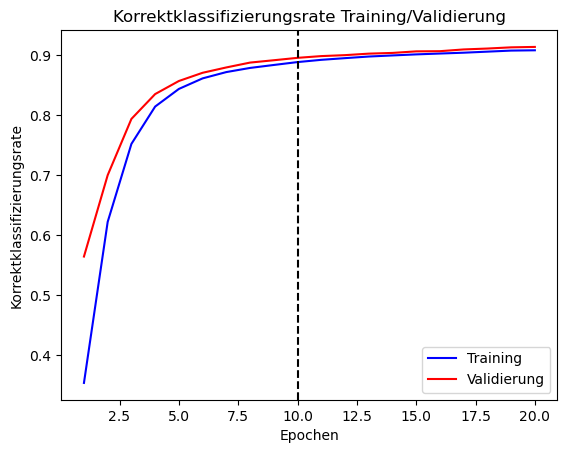

In [11]:
# Aufgabe 18.2.2: Validierungsdaten über validation_data=(x_test, y_test_onehot) übergeben
# Neues Modell, damit nicht auf dem schon trainierten weitertrainiert wird
def build_model():
    m = keras.Sequential()
    m.add(keras.layers.Dense(64, activation="relu", input_shape=(784,)))
    m.add(keras.layers.Dense(10, activation="softmax"))
    m.compile(optimizer="rmsprop", loss="categorical_crossentropy", metrics=["accuracy"])
    return m

model = build_model()
history = model.fit(x_train, y_train_onehot, epochs=20, batch_size=64,
                    validation_data=(x_test, y_test_onehot))

# Hinweis aus der Aufgabe: welche Keys gibt es?
print(history.history.keys())  # accuracy, loss, val_accuracy, val_loss

epochs = len(history.history['accuracy'])
plt.plot(range(1, epochs + 1), history.history['accuracy'], 'b', label="Training")
plt.plot(range(1, epochs + 1), history.history['val_accuracy'], 'r', label="Validierung")
plt.axvline(x=10, color='k', linestyle='--')  # strichlierte Linie bei Epoche 10
plt.title("Korrektklassifizierungsrate Training/Validierung")
plt.xlabel("Epochen")
plt.ylabel("Korrektklassifizierungsrate")
plt.legend()
plt.show()

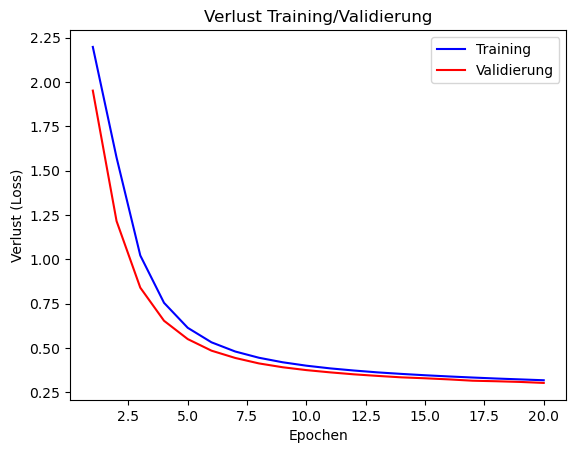

C:\Users\fabio\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


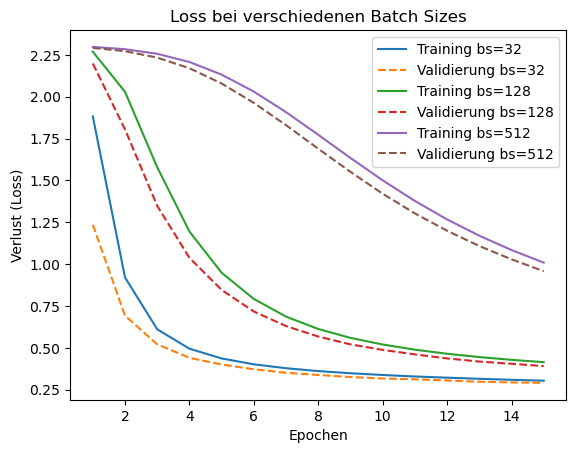

In [13]:
# Aufgabe 18.2.3: Plot der Verlustfunktion (loss und val_loss)
epochs = len(history.history['loss'])
plt.plot(range(1, epochs + 1), history.history['loss'], 'b', label="Training")
plt.plot(range(1, epochs + 1), history.history['val_loss'], 'r', label="Validierung")
plt.title("Verlust Training/Validierung")
plt.xlabel("Epochen")
plt.ylabel("Verlust (Loss)")
plt.legend()
plt.show()

# Experimente mit verschiedenen Epochen / Batch Sizes
for bs in [32, 128, 512]:
    m = build_model()
    h = m.fit(x_train, y_train_onehot, epochs=15, batch_size=bs,
              validation_data=(x_test, y_test_onehot), verbose=0)
    n = len(h.history['loss'])
    plt.plot(range(1, n + 1), h.history['loss'], label=f"Training bs={bs}")
    plt.plot(range(1, n + 1), h.history['val_loss'], '--', label=f"Validierung bs={bs}")

plt.title("Loss bei verschiedenen Batch Sizes")
plt.xlabel("Epochen")
plt.ylabel("Verlust (Loss)")
plt.legend()
plt.show()

In [14]:
# Aufgabe 18.2.4: Modell speichern
model.save("mnist_model.keras")